### The inverse travelling wave

HSG 22.09

In [1]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

In [2]:
import numpy as np 
import matplotlib.pyplot as plt 
from nonlinear.spectralNewton import solve_with_continuation

In [3]:
# -- Set-up --
N = 2**8
L = 8*np.pi
x = np.linspace(-L/2, L/2, N, endpoint=False)
k = 2*np.pi*np.fft.fftfreq(N, d = L/N)

# -- Soliton Travelling
def soliton_profile(x,c,x0=0.0):
    return (c/2)/np.cosh(np.sqrt(c)/2 * (x-x0))**2

In [4]:
c_values = np.array([0.5 , 1.0 , 1.5, 2.0 , 2.5])
n_samples = len(c_values)

phi_hat_list = []
nl_hat_list = []
dHdt_hat_list = []

for c in c_values:
    H = soliton_profile(x,c)
    H_hat = np.fft.fft(H)
    H2_hat = np.fft.fft(H**2)
    dHdt_hat = -1j*k*c*H_hat

    phi_hat_list.append(H_hat)
    nl_hat_list.append(H2_hat)
    dHdt_hat_list.append(dHdt_hat)

phi_hat =   np.stack(phi_hat_list,   axis = 1)
nl_hat =    np.stack(nl_hat_list,    axis = 1)
dHdt_hat =  np.stack(dHdt_hat_list,  axis = 1)

In [5]:
A = np.stack([phi_hat, nl_hat], axis= 1)
A_pinv = np.linalg.pinv(A)
X = np.einsum('fs,fsc->fc', dHdt_hat,A_pinv)

ell = X[:,0]
n   = X[:,1]

In [26]:
def m_kdv(k):
    return k**3

mk = m_kdv(k)

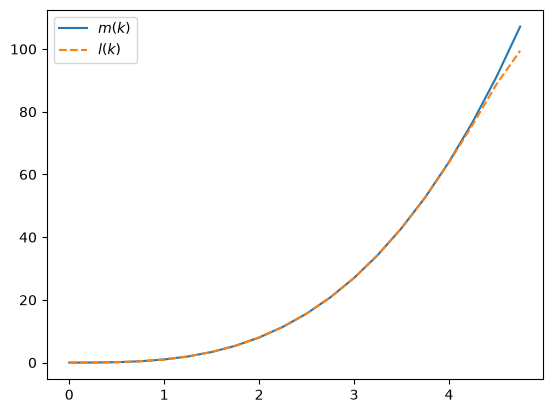

In [33]:
idx = 20
plt.plot(k[-N-2*idx:idx], mk[-N-2*idx:idx] , label = r"$m(k)$")
plt.plot(k[-N-2*idx:idx], ell.imag[-N-2*idx:idx], '--', label = r"$l(k)$")
plt.legend()
plt.show()


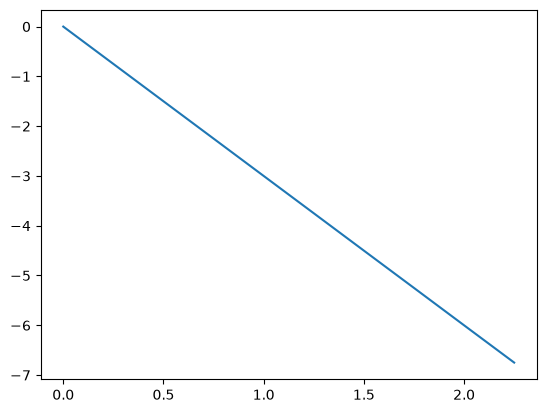

In [25]:
idx = 10
# plt.plot(k[:idx], mk[:idx])
plt.plot(k[:idx], n.imag[:idx])